# Текущий контроль 7–8. Бинарная логистическая регрессия

**Задание.** Реализовать класс модели логистической регрессии, обучаемой двумя способами:

* **а)** максимизацией логарифмического правдоподобия методом градиентного **подъёма**;
* **б)** минимизацией функции потерь (кросс-энтропии) методом градиентного **спуска**.

Сравнить результаты (время исполнения и достигнутые значения accuracy и F1) в случаях а и б при одном и том же числе шагов и скорости обучения. Затем применить обе версии к набору `insclass_train.csv` (страховые договоры, `target = 1` — рискованный договор).

**План работы.**

1. Постановка и теория: почему линейная регрессия не годится для классификации, сигмоида, правдоподобие, кросс-энтропия, градиенты, метрики качества.
2. Реализация: свои функции метрик (с проверкой по `sklearn.metrics`) и класс `LogisticRegressionGD`.
3. Игрушечный пример «расходы на рекламу».
4. Основной эксперимент на `insclass_train.csv`: подготовка данных, подбор скорости обучения, сравнение способов а и б.
5. Подбор порога классификации при дисбалансе классов.
6. Выводы.

## 1. Постановка задачи и теория

### 1.1. Бинарная классификация

Каждый объект описывается вектором признаков $x \in \mathbb{R}^{m}$, ответ $y \in \{0, 1\}$. Нужно по обучающей выборке из $n$ объектов построить правило, которое предсказывает $y$ для новых объектов.

Матрицу признаков запишем как $X \in \mathbb{R}^{n \times (m+1)}$, где первый столбец состоит из единиц (так свободный член $\theta_0$ становится обычным коэффициентом). Вектор ответов обозначим $y \in \{0,1\}^n$, вектор параметров — $\theta \in \mathbb{R}^{m+1}$.

### 1.2. Почему не подходит линейная регрессия

Возьмём игрушечный набор данных: $x$ — расходы фирмы на рекламу, $y = 1$, если эффект от рекламы был, и $y = 0$, если нет. Попробуем обычную линейную регрессию (метод наименьших квадратов) и будем относить объект к классу 1, если прогноз не меньше $0.5$.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix as sk_confusion_matrix, log_loss, roc_auc_score)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
SEED = 42

Точек: 22, из них с эффектом (y = 1): 12
все 22 точки          : y = 0.2665 + 0.00633·x; прогноз при x = 0: 0.266, при x = 200: 1.533; уровень 0.5 при x = 36.9; доля верных на своих 22 точках: 0.818
без x = 100 и x = 200 : y = -0.1539 + 0.01955·x; прогноз при x = 0: -0.154, при x = 200: 3.756; уровень 0.5 при x = 33.5; доля верных на своих 20 точках: 0.750


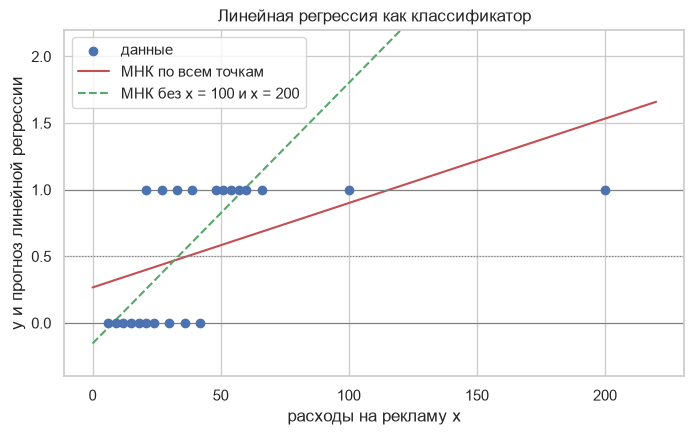

In [2]:
# Игрушечные данные: x — расходы на рекламу, y = 1, если эффект от рекламы был
x_toy = np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200], dtype=float)
y_toy = np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1], dtype=float)
print(f'Точек: {len(x_toy)}, из них с эффектом (y = 1): {int(y_toy.sum())}')


def fit_line(x, y):
    """МНК для y ≈ a0 + a1·x (через ковариацию и дисперсию)."""
    a1 = np.mean((x - x.mean()) * (y - y.mean())) / np.mean((x - x.mean()) ** 2)
    return y.mean() - a1 * x.mean(), a1


a0_all, a1_all = fit_line(x_toy, y_toy)
near = x_toy <= 70                      # без двух далёких точек x = 100 и x = 200
a0_near, a1_near = fit_line(x_toy[near], y_toy[near])

for name, a0, a1, mask in [('все 22 точки', a0_all, a1_all, np.ones(len(x_toy), dtype=bool)),
                           ('без x = 100 и x = 200', a0_near, a1_near, near)]:
    acc = np.mean((a0 + a1 * x_toy[mask] >= 0.5) == y_toy[mask])
    print(f'{name:22s}: y = {a0:.4f} + {a1:.5f}·x; прогноз при x = 0: {a0:.3f}, при x = 200: {a0 + a1 * 200:.3f}; '
          f'уровень 0.5 при x = {(0.5 - a0) / a1:.1f}; доля верных на своих {mask.sum()} точках: {acc:.3f}')

xs = np.linspace(0, 220, 441)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x_toy, y_toy, color='C0', zorder=3, label='данные')
ax.plot(xs, a0_all + a1_all * xs, color='C3', label='МНК по всем точкам')
ax.plot(xs, a0_near + a1_near * xs, color='C2', ls='--', label='МНК без x = 100 и x = 200')
ax.axhline(0, color='gray', lw=0.8)
ax.axhline(1, color='gray', lw=0.8)
ax.axhline(0.5, color='gray', lw=0.8, ls=':')
ax.set_ylim(-0.4, 2.2)
ax.set_xlabel('расходы на рекламу x')
ax.set_ylabel('y и прогноз линейной регрессии')
ax.set_title('Линейная регрессия как классификатор')
ax.legend()
plt.show()

Что видно на графике и в выводе ячейки:

* **Прогноз прямой не является вероятностью.** При $x = 200$ прямая по всем точкам даёт 1.533, а прямая без двух далёких точек — 3.756. Значения выходят за границы $[0, 1]$ и в другую сторону: у второй прямой при $x = 0$ получается −0.154.
* **Далёкие точки сдвигают границу.** Точки $x = 100$ и $x = 200$ относятся к классу 1 и не должны менять границу между классами. Но они наклоняют прямую: уровень 0.5 смещается с $x = 33.5$ до $x = 36.9$.
* **По доле верных ответов прямая не безнадёжна** (0.818 на 22 точках и 0.750 на 20 точках), но проблема не в этой цифре: значения прямой нельзя читать как вероятности, а положение границы зависит от далёких точек.

Логистическая регрессия убирает обе проблемы: сигмоида не выходит из $[0, 1]$, а граница классов, как увидим в разделе 3, от далёких точек практически не зависит.

### 1.3. Сигмоида и модель

Выход линейной части $z = \theta^\top x$ может быть любым числом, а вероятность должна лежать в $[0, 1]$. Пропустим $z$ через сигмоиду:

$$\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad \sigma'(z) = \sigma(z)\bigl(1 - \sigma(z)\bigr).$$

Модель логистической регрессии:

$$h_\theta(x) = P(y = 1 \mid x) = \sigma(\theta^\top x).$$

Класс предсказываем по порогу: $\hat y = 1$, если $h_\theta(x) \ge \tau$. По умолчанию $\tau = 0.5$, что равносильно $\theta^\top x \ge 0$. Граница классов $\theta^\top x = 0$ — гиперплоскость, поэтому модель линейная.

### 1.4. Логарифмическое правдоподобие и кросс-энтропия

Для одного объекта вероятность наблюдаемого ответа равна $h_i^{\,y_i}(1 - h_i)^{1 - y_i}$, где $h_i = h_\theta(x_i)$. Если объекты независимы, правдоподобие выборки — произведение таких множителей. Логарифм превращает произведение в сумму. Мы берём **среднее** по выборке (деление на $n$ не меняет точку максимума, зато шаг $\alpha$ не зависит от размера выборки):

$$LL(\theta) = \frac{1}{n} \sum_{i=1}^{n} \Bigl[ y_i \ln h_i + (1 - y_i) \ln (1 - h_i) \Bigr].$$

Функция потерь — бинарная кросс-энтропия (log loss):

$$CE(\theta) = -LL(\theta) = -\frac{1}{n} \sum_{i=1}^{n} \Bigl[ y_i \ln h_i + (1 - y_i) \ln (1 - h_i) \Bigr].$$

Так что **максимизировать $LL$ и минимизировать $CE$ — одна и та же задача**: для любого $\theta$ верно $LL(\theta) = -CE(\theta)$.

Среднеквадратичную ошибку здесь не берут: после подстановки сигмоиды она перестаёт быть выпуклой по $\theta$ и появляются локальные минимумы. А $CE$ по $\theta$ выпукла: её матрица вторых производных $\frac{1}{n} X^\top \mathrm{diag}\bigl(h_i (1 - h_i)\bigr) X$ неотрицательно определена.

### 1.5. Градиенты и два способа обучения

Для одного объекта, с учётом $\sigma' = \sigma(1 - \sigma)$:

$$\frac{\partial}{\partial \theta}\Bigl[y \ln h + (1 - y)\ln(1 - h)\Bigr] = \Bigl(\frac{y}{h} - \frac{1 - y}{1 - h}\Bigr) h (1 - h)\, x = (y - h)\, x.$$

В матричном виде:

$$\nabla LL(\theta) = \frac{1}{n} X^\top (y - h), \qquad \nabla CE(\theta) = -\nabla LL(\theta) = \frac{1}{n} X^\top (h - y),$$

где $h = \sigma(X\theta)$ — вектор вероятностей.

Два способа обучения с одним и тем же начальным $\theta^{(0)} = 0$, скоростью обучения $\alpha$ и числом шагов $K$:

| способ | правило шага |
|---|---|
| **а)** градиентный подъём по $LL$ | $\theta^{(k+1)} = \theta^{(k)} + \alpha\, \nabla LL\bigl(\theta^{(k)}\bigr)$ |
| **б)** градиентный спуск по $CE$ | $\theta^{(k+1)} = \theta^{(k)} - \alpha\, \nabla CE\bigl(\theta^{(k)}\bigr)$ |

Что из этого следует для сравнения способов, разберём в выводах, а численно проверим в разделе 4.7.

### 1.6. Оценка качества классификации

Матрица ошибок (confusion matrix) для классов 0 и 1:

| | Прогноз: 0 | Прогноз: 1 |
|---|---|---|
| **Факт: 0** | TN (верно отрицательные) | FP (ложно положительные) |
| **Факт: 1** | FN (ложно отрицательные) | TP (верно положительные) |

$$\text{accuracy} = \frac{TP + TN}{TP + TN + FP + FN}, \qquad \text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN},$$

$$F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}} = \frac{2\,TP}{2\,TP + FP + FN}.$$

Если знаменатель равен нулю (например, модель не предсказала ни одной единицы и precision не определён), метрику принимаем равной 0 — так же, как `zero_division=0` в `sklearn`. F1 всегда считаем по классу 1 (рискованный договор).

При дисбалансе классов одной accuracy недостаточно: модель «всегда отвечает 0» при доле единиц около 8 % получает accuracy около 92 %, но не находит ни одного рискованного договора. Поэтому ниже главная метрика — F1 по классу 1.

## 2. Реализация

### 2.1. Метрики на numpy

Все метрики считаем по матрице ошибок `[[TN, FP], [FN, TP]]`.

In [3]:
def confusion_matrix_np(y_true, y_pred):
    """Матрица ошибок [[TN, FP], [FN, TP]] для меток 0/1."""
    y_true = np.asarray(y_true).astype(int).ravel()
    y_pred = np.asarray(y_pred).astype(int).ravel()
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])


def accuracy(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    return float((tn + tp) / (tn + fp + fn + tp))


def precision(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    return float(tp / (tp + fp)) if tp + fp > 0 else 0.0


def recall(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    return float(tp / (tp + fn)) if tp + fn > 0 else 0.0


def f1(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    return float(2 * tp / (2 * tp + fp + fn)) if 2 * tp + fp + fn > 0 else 0.0

### 2.2. Проверка метрик по `sklearn.metrics`

Сравниваем свои функции с `sklearn` на случайных данных с разной долей единиц и разной долей предсказанных единиц. Последний случай — модель, которая вообще не предсказывает единицы (precision не определён).

In [4]:
rng_check = np.random.default_rng(SEED)
cases = [  # (доля единиц в y_true, доля единиц в y_pred)
    (0.50, 0.50), (0.08, 0.30), (0.08, 0.02), (0.30, 0.10), (0.08, 0.00),
]
rows = []
for share_true, share_pred in cases:
    y_t = (rng_check.random(2000) < share_true).astype(int)
    y_p = (rng_check.random(2000) < share_pred).astype(int)
    ours = [accuracy(y_t, y_p), precision(y_t, y_p), recall(y_t, y_p), f1(y_t, y_p)]
    theirs = [accuracy_score(y_t, y_p),
              precision_score(y_t, y_p, zero_division=0),
              recall_score(y_t, y_p, zero_division=0),
              f1_score(y_t, y_p, zero_division=0)]
    rows.append({
        'доля 1 в y': share_true, 'доля 1 в прогнозе': share_pred,
        'max |разница| метрик': np.max(np.abs(np.array(ours) - np.array(theirs))),
        'матрица ошибок совпала': bool(np.array_equal(confusion_matrix_np(y_t, y_p),
                                                       sk_confusion_matrix(y_t, y_p, labels=[0, 1]))),
    })
check = pd.DataFrame(rows)
display(check)
assert (check['max |разница| метрик'] < 1e-12).all() and check['матрица ошибок совпала'].all()
print('Свои метрики совпали с sklearn.metrics во всех случаях.')

# наглядный пример: один случай «рядом»
y_t = (rng_check.random(2000) < 0.08).astype(int)
y_p = (rng_check.random(2000) < 0.30).astype(int)
display(pd.DataFrame({
    'свои функции': [accuracy(y_t, y_p), precision(y_t, y_p), recall(y_t, y_p), f1(y_t, y_p)],
    'sklearn.metrics': [accuracy_score(y_t, y_p), precision_score(y_t, y_p), recall_score(y_t, y_p), f1_score(y_t, y_p)],
}, index=['accuracy', 'precision', 'recall', 'F1']).round(6))

,доля 1 в y,доля 1 в прогнозе,max |разница| метрик,матрица ошибок совпала
0,0.50,0.50,0.0,True
1,0.08,0.30,0.0,True
2,0.08,0.02,0.0,True
3,0.30,0.10,0.0,True
4,0.08,0.00,0.0,True


Свои метрики совпали с sklearn.metrics во всех случаях.


,свои функции,sklearn.metrics
accuracy,0.667000,0.667000
precision,0.074450,0.074450
recall,0.269939,0.269939
F1,0.116711,0.116711


### 2.3. Класс `LogisticRegressionGD`

Что важно в реализации:

* Всё векторизовано (`X @ theta`, `X.T @ ...`), внутри цикла по шагам ничего не печатается.
* Сигмоида устойчива: аргумент обрезается до $[-500, 500]$, `exp` не переполняется.
* Логарифмы устойчивы: вероятности обрезаются до $[10^{-12}, 1 - 10^{-12}]$, поэтому `log(0)` не возникает.
* `fit(..., mode='LL')` — градиентный подъём по средней $LL$; `fit(..., mode='CE')` — градиентный спуск по средней $CE$. Остальное (начальное $\theta = 0$, $\alpha$, число шагов) одинаково.
* В `history` записывается значение оптимизируемой функции на каждом шаге до обновления и ещё одно значение в конце (для режима `'LL'` это $LL$, для `'CE'` это $CE$), всего `max_steps + 1` значений. Вероятности $h$ на шаге считаются один раз и используются и для функции, и для градиента.
* Столбец единиц (свободный член) добавляется снаружи: `X` уже должен его содержать.

In [5]:
class LogisticRegressionGD:
    """Бинарная логистическая регрессия, обучаемая полным (батчевым) градиентным шагом.

    mode='LL' — градиентный подъём по средней лог-правдоподобности,
    mode='CE' — градиентный спуск по средней кросс-энтропии.
    """
    EPS = 1e-12   # защита логарифма от нуля

    def __init__(self):
        self.theta = None
        self.history = None
        self.mode = None

    @staticmethod
    def sigmoid(z):
        # обрезка z не даёт exp переполниться
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def predict_proba(self, X):
        return self.sigmoid(X @ self.theta)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    @classmethod
    def _mean_loglik(cls, p, y):
        p = np.clip(p, cls.EPS, 1.0 - cls.EPS)
        return np.mean(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))

    def LogLikelihood(self, X, y):
        return self._mean_loglik(self.predict_proba(X), np.asarray(y, dtype=float).ravel())

    def CrossEntropy(self, X, y):
        return -self.LogLikelihood(X, y)

    def fit(self, X, y, alpha=0.1, max_steps=1000, mode='LL'):
        if mode not in ('LL', 'CE'):
            raise ValueError("mode должен быть 'LL' или 'CE'")
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        n = X.shape[0]
        theta = np.zeros(X.shape[1])
        sign = 1.0 if mode == 'LL' else -1.0          # история: LL или CE = −LL
        history = np.empty(max_steps + 1)
        for k in range(max_steps):
            p = self.sigmoid(X @ theta)
            history[k] = sign * self._mean_loglik(p, y)
            if mode == 'LL':
                theta += alpha * (X.T @ (y - p)) / n   # подъём:  θ ← θ + α·∇LL
            else:
                theta -= alpha * (X.T @ (p - y)) / n   # спуск:   θ ← θ − α·∇CE
        history[max_steps] = sign * self._mean_loglik(self.sigmoid(X @ theta), y)
        self.theta, self.history, self.mode = theta, history, mode
        return self

## 3. Игрушечный пример: расходы на рекламу

Обучим модель обоими способами с параметрами из исходной работы: $\alpha = 0.01$, $10\,000$ шагов. Признак здесь один, $x$ в «сырых» единицах (от 6 до 200), плюс столбец единиц. Результат сверим с `sklearn.linear_model.LogisticRegression` с очень слабой регуляризацией (`C = 1e6`, то есть почти без неё). Заодно проверим, что свой `CrossEntropy` совпадает с `sklearn.metrics.log_loss`.

In [6]:
X_toy = np.column_stack([np.ones(len(x_toy)), x_toy])

toy_LL = LogisticRegressionGD().fit(X_toy, y_toy, alpha=0.01, max_steps=10000, mode='LL')
toy_CE = LogisticRegressionGD().fit(X_toy, y_toy, alpha=0.01, max_steps=10000, mode='CE')
toy_sk = LogisticRegression(C=1e6, tol=1e-12, max_iter=100000).fit(x_toy.reshape(-1, 1), y_toy)

# тот же алгоритм на стандартизованном x (с пересчётом коэффициентов обратно в «сырой» масштаб)
mu_x, sd_x = x_toy.mean(), x_toy.std()
X_toy_z = np.column_stack([np.ones(len(x_toy)), (x_toy - mu_x) / sd_x])
toy_z = LogisticRegressionGD().fit(X_toy_z, y_toy, alpha=1.0, max_steps=3000, mode='CE')
theta_z_raw = np.array([toy_z.theta[0] - toy_z.theta[1] * mu_x / sd_x, toy_z.theta[1] / sd_x])


def toy_row(name, th0, th1):
    p = LogisticRegressionGD.sigmoid(th0 + th1 * x_toy)
    return {'модель': name, 'θ0 (свободный член)': th0, 'θ1 (при x)': th1,
            'CE (log_loss)': log_loss(y_toy, p),
            'accuracy': accuracy(y_toy, p >= 0.5), 'F1': f1(y_toy, p >= 0.5)}


toy_table = pd.DataFrame([
    toy_row('а) подъём по LL, x «сырой», α=0.01, 10000 шагов', *toy_LL.theta),
    toy_row('б) спуск по CE, x «сырой», α=0.01, 10000 шагов', *toy_CE.theta),
    toy_row('б) спуск по CE, x стандартизован, α=1, 3000 шагов', *theta_z_raw),
    toy_row('sklearn LogisticRegression(C=1e6)', toy_sk.intercept_[0], toy_sk.coef_[0, 0]),
]).set_index('модель')
display(toy_table.round(5))

print('max |θ_LL − θ_CE| (сырой x)           =', np.max(np.abs(toy_LL.theta - toy_CE.theta)))
for name, h in [('сырой x, α = 0.01', toy_CE.history), ('стандартизованный x, α = 1', toy_z.history)]:
    up = np.where(np.diff(h) > 1e-9)[0]      # шаги, на которых CE заметно выросла
    print(f'{name}: CE выросла на {len(up)} шагах из {len(h) - 1}; последний такой шаг: '
          f'{int(up.max()) + 1 if len(up) else "нет"}')
print('CrossEntropy() класса и sklearn.metrics.log_loss отличаются на',
      abs(toy_CE.CrossEntropy(X_toy, y_toy) - log_loss(y_toy, toy_CE.predict_proba(X_toy))))
print(f'Средняя CE на шаге 10000 (сырой x): {toy_CE.history[-1]:.5f}; в оптимуме (sklearn): '
      f'{toy_table.loc["sklearn LogisticRegression(C=1e6)", "CE (log_loss)"]:.5f}')

# граница классов x* = −θ0/θ1: сдвигается ли она, если убрать две далёкие точки (как для МНК выше)?
sk_near = LogisticRegression(C=1e6, tol=1e-12, max_iter=100000).fit(x_toy[near].reshape(-1, 1), y_toy[near])
print(f'Граница классов x* = −θ0/θ1: у модели на «сыром» x после 10000 шагов {-toy_CE.theta[0] / toy_CE.theta[1]:.2f}, '
      f'у sklearn {-toy_sk.intercept_[0] / toy_sk.coef_[0, 0]:.2f}; между ними лежит точек: '
      f'{int(np.sum((x_toy > -toy_CE.theta[0] / toy_CE.theta[1]) & (x_toy < -toy_sk.intercept_[0] / toy_sk.coef_[0, 0])))}')
print(f'Граница классов логистической регрессии (sklearn): по 22 точкам x* = {-toy_sk.intercept_[0] / toy_sk.coef_[0, 0]:.2f}, '
      f'по 20 точкам (без x = 100 и 200) x* = {-sk_near.intercept_[0] / sk_near.coef_[0, 0]:.2f}')
print(f'Для сравнения, уровень 0.5 у линейной регрессии: {(0.5 - a0_near) / a1_near:.1f} и {(0.5 - a0_all) / a1_all:.1f}')

,θ0 (свободный член),θ1 (при x),CE (log_loss),accuracy,F1
модель,,,,,
"а) подъём по LL, x «сырой», α=0.01, 10000 шагов",-3.59905,0.11216,0.36681,0.81818,0.83333
"б) спуск по CE, x «сырой», α=0.01, 10000 шагов",-3.59905,0.11216,0.36681,0.81818,0.83333
"б) спуск по CE, x стандартизован, α=1, 3000 шагов",-4.07888,0.12543,0.36500,0.81818,0.83333
sklearn LogisticRegression(C=1e6),-4.07888,0.12543,0.36500,0.81818,0.83333


max |θ_LL − θ_CE| (сырой x)           = 0.0
сырой x, α = 0.01: CE выросла на 1111 шагах из 10000; последний такой шаг: 2089
стандартизованный x, α = 1: CE выросла на 0 шагах из 3000; последний такой шаг: нет
CrossEntropy() класса и sklearn.metrics.log_loss отличаются на 0.0
Средняя CE на шаге 10000 (сырой x): 0.36681; в оптимуме (sklearn): 0.36500
Граница классов x* = −θ0/θ1: у модели на «сыром» x после 10000 шагов 32.09, у sklearn 32.52; между ними лежит точек: 0
Граница классов логистической регрессии (sklearn): по 22 точкам x* = 32.52, по 20 точкам (без x = 100 и 200) x* = 32.52
Для сравнения, уровень 0.5 у линейной регрессии: 33.5 и 36.9


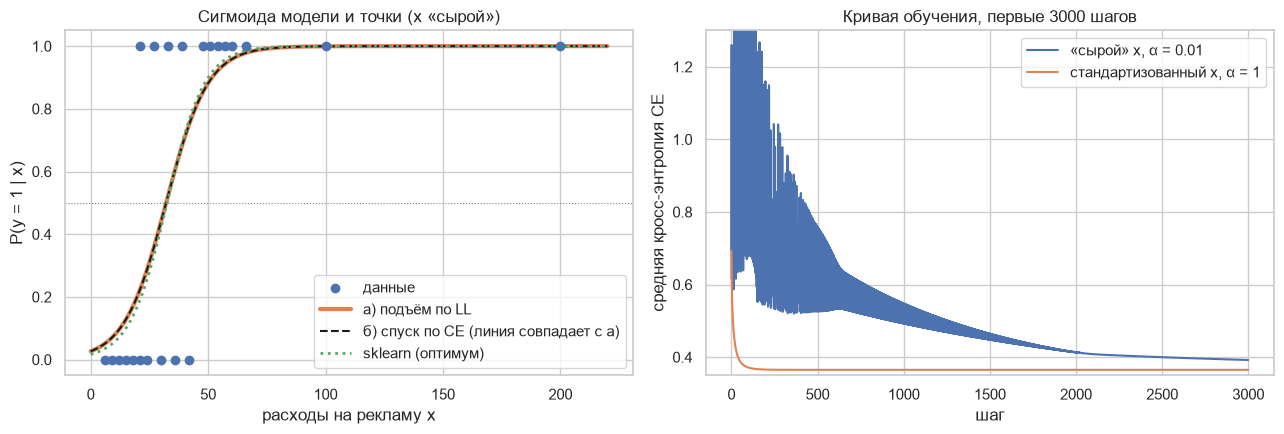

In [7]:
xs = np.linspace(0, 220, 441)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.scatter(x_toy, y_toy, color='C0', zorder=3, label='данные')
ax.plot(xs, LogisticRegressionGD.sigmoid(toy_LL.theta[0] + toy_LL.theta[1] * xs), color='C1', lw=3, label='а) подъём по LL')
ax.plot(xs, LogisticRegressionGD.sigmoid(toy_CE.theta[0] + toy_CE.theta[1] * xs), color='k', ls='--', label='б) спуск по CE (линия совпадает с а)')
ax.plot(xs, LogisticRegressionGD.sigmoid(toy_sk.intercept_[0] + toy_sk.coef_[0, 0] * xs), color='C2', ls=':', lw=2, label='sklearn (оптимум)')
ax.axhline(0.5, color='gray', lw=0.8, ls=':')
ax.set_xlabel('расходы на рекламу x')
ax.set_ylabel('P(y = 1 | x)')
ax.set_title('Сигмоида модели и точки (x «сырой»)')
ax.legend(loc='lower right')

ax = axes[1]
steps_show = 3000
ax.plot(np.arange(steps_show), toy_CE.history[:steps_show], label='«сырой» x, α = 0.01')
ax.plot(np.arange(steps_show), toy_z.history[:steps_show], label='стандартизованный x, α = 1')
ax.set_ylim(0.35, 1.3)
ax.set_xlabel('шаг')
ax.set_ylabel('средняя кросс-энтропия CE')
ax.set_title(f'Кривая обучения, первые {steps_show} шагов')
ax.legend()
plt.tight_layout()
plt.show()

Что видно:

* **Способы а и б дают одно и то же.** Параметры совпадают ($\theta_0 = -3.59905$, $\theta_1 = 0.11216$), $\max|\theta_{LL} - \theta_{CE}| = 0.0$, кривые сигмоид на левом графике накладываются друг на друга. Свой `CrossEntropy` совпал с `sklearn.metrics.log_loss`.
* **На «сырых» $x$ за 10000 шагов до оптимума дойти не удалось.** Средняя $CE$ равна 0.36681 против 0.36500 в оптимуме (sklearn), а параметры $(-3.599;\ 0.1122)$ заметно отличаются от оптимальных $(-4.079;\ 0.1254)$. Причина видна на правом графике: $x$ доходит до 200, при $\alpha = 0.01$ шаг слишком велик для «крутого» направления, и $CE$ колеблется. Она выросла на 1111 шагах из 10000, последний раз на шаге 2089, а затем медленно ползёт вниз. Точные числа 1111 и 2089 чувствительны к порядку арифметических операций и на другой машине или версии библиотеки могут немного отличаться; качественная картина (колебания в начале, затем медленное убывание) устойчива.
* **Для классификации этого хватило.** Accuracy 0.81818 и F1 0.83333 одинаковы у всех четырёх моделей: граница классов $x^* = -\theta_0/\theta_1$ у недообученной модели 32.09, у sklearn 32.52, и между этими значениями нет ни одной точки.
* **После стандартизации $x$ картина другая.** При $\alpha = 1$ кривая обучения гладкая: $CE$ не выросла ни на одном шаге из 3000. Коэффициенты, пересчитанные обратно в исходный масштаб, совпадают с sklearn до пяти знаков ($-4.07888$ и $0.12543$). Поэтому в основном эксперименте признаки стандартизуются.
* **Граница логистической регрессии устойчива к далёким точкам, лежащим на «своей» стороне границы** (здесь $x = 100$ и $x = 200$ относятся к классу 1; если бы метки у них были обратными, граница сдвинулась бы сильно): по 22 точкам $x^* = 32.52$, по 20 точкам (без $x = 100$ и $x = 200$) тоже 32.52. У линейной регрессии из раздела 1.2 уровень 0.5 сдвигался с 33.5 до 36.9.

## 4. Основной эксперимент: `insclass_train.csv`

Для 151 406 договоров страхования транспортных средств известны признаки водителя и автомобиля и признак `target`: 1 — заключение договора с клиентом рисковое, 0 — нет. По заданию берём десять признаков:

| столбец | смысл |
|---|---|
| `variable_4` | идентификатор года выпуска транспортного средства |
| `variable_6` | мощность двигателя, л. с. |
| `variable_12` | возраст транспортного средства, мес. |
| `variable_13` | возраст водителя с максимальным стажем |
| `variable_14` | коэффициент «возраст-стаж» |
| `variable_16` | коэффициент мощности |
| `variable_17` | коэффициент «мультидрайв» |
| `variable_18` | территориальный коэффициент |
| `variable_19` | коэффициент «КНДР» |
| `variable_27` | стаж водителя с максимальным коэффициентом «возраст-стаж» |

### 4.1. Загрузка и пропуски

In [8]:
FEATURES = ['variable_4', 'variable_6', 'variable_12', 'variable_13', 'variable_14',
            'variable_16', 'variable_17', 'variable_18', 'variable_19', 'variable_27']
df_raw = pd.read_csv('insclass_train.csv', header=0, usecols=FEATURES + ['target'])
print('Размер таблицы:', df_raw.shape)
print('Пропусков по столбцам (только где они есть):')
display(df_raw.isna().sum()[lambda s: s > 0].to_frame('пропусков'))

df = df_raw.dropna()
rows_with_gaps = df_raw.isna().any(axis=1)
print(f'Удалено строк: {len(df_raw) - len(df)} из {len(df_raw)} ({rows_with_gaps.mean():.2%}); осталось {len(df)}')
print(f'Доля target = 1: во всей таблице {df_raw.target.mean():.2%}, в удалённых строках '
      f'{df_raw.target[rows_with_gaps].mean():.2%}, в оставшихся {df.target.mean():.2%}')
display(df[FEATURES].describe().T[['mean', 'std', 'min', 'max']].round(2))

Размер таблицы: (151406, 11)
Пропусков по столбцам (только где они есть):


,пропусков
variable_6,111
variable_12,1528
variable_13,1657
variable_14,2927
variable_16,12
variable_17,12
variable_18,12
variable_27,2067


Удалено строк: 4877 из 151406 (3.22%); осталось 146529
Доля target = 1: во всей таблице 9.55%, в удалённых строках 48.64%, в оставшихся 8.25%


,mean,std,min,max
variable_4,11.39,6.91,2.00,80.00
variable_6,117.57,49.80,1.00,1975.00
variable_12,133.20,87.92,0.00,842.77
variable_13,49.99,15.49,20.73,115.58
variable_14,87.35,31.93,80.99,273.41
variable_16,132.12,42.37,28.13,214.26
variable_17,81.81,12.57,80.99,273.41
variable_18,109.21,67.50,19.29,376.18
variable_19,140.00,18.58,102.17,284.37
variable_27,15.53,11.99,0.00,100.56


В файле 151406 строк; пропуски есть в восьми из десяти выбранных столбцов. `dropna` удаляет 4877 строк (3.22 %), остаётся 146529. Удалённые строки не случайны: доля рискованных договоров в них 48.64 %, а в оставшихся 8.25 % (во всей таблице 9.55 %). Дальше работаем с оставшимися строками, как требует задание, но это важная оговорка к результатам (см. выводы). Класс 1 редкий, поэтому одной accuracy качество мерить нельзя.

### 4.2. Разбиение 70 / 15 / 15 и стандартизация

Строки перемешиваем с фиксированным seed и делим на обучающую (train), валидационную (validation) и тестовую (test) части. Среднее и стандартное отклонение для стандартизации считаем **только по train** и применяем к validation и test, чтобы информация о проверочных данных не попала в обучение. Столбец единиц добавляем после стандартизации (его не нужно масштабировать).

Зачем стандартизация: признаки имеют разный масштаб (мощность до 1975 л. с., коэффициенты порядка 100, годы порядка 10). При разных масштабах поверхность $CE$ сильно вытянута, и градиентный спуск с одним $\alpha$ либо медленно сходится, либо «прыгает» (это видно в игрушечном примере).

In [9]:
X_raw = df[FEATURES].to_numpy(dtype=float)
y_all = df['target'].to_numpy(dtype=float)

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(df))
n_train, n_val = int(0.70 * len(df)), int(0.85 * len(df))
idx_train, idx_val, idx_test = np.split(perm, [n_train, n_val])

mu = X_raw[idx_train].mean(axis=0)       # статистики — только по train
sigma = X_raw[idx_train].std(axis=0)


def prepare(idx):
    Z = (X_raw[idx] - mu) / sigma
    return np.column_stack([np.ones(len(idx)), Z])


X_train, X_val, X_test = prepare(idx_train), prepare(idx_val), prepare(idx_test)
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]

print(pd.DataFrame({
    'объектов': [len(y_train), len(y_val), len(y_test)],
    'доля target = 1': [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=['train', 'validation', 'test']).round(4))
display(pd.DataFrame({'среднее (train)': mu, 'σ (train)': sigma}, index=FEATURES).round(3))

# сильно коррелированные признаки замедляют сходимость
corr = np.corrcoef(X_train[:, 1:].T)
np.fill_diagonal(corr, 0)
i, j = np.unravel_index(np.abs(corr).argmax(), corr.shape)
print(f'Самая коррелированная пара признаков: {FEATURES[i]} и {FEATURES[j]}, r = {corr[i, j]:.3f}')

            объектов  доля target = 1
train         102570           0.0826
validation     21979           0.0842
test           21980           0.0802


,среднее (train),σ (train)
variable_4,11.392,6.901
variable_6,117.715,50.211
variable_12,133.248,87.797
variable_13,50.040,15.497
variable_14,87.299,31.808
variable_16,132.244,42.402
variable_17,81.786,12.390
variable_18,109.181,67.380
variable_19,139.979,18.571
variable_27,15.587,12.004


Самая коррелированная пара признаков: variable_4 и variable_12, r = 0.990


Доля единиц в трёх частях близка: 0.0826 (train), 0.0842 (validation), 0.0802 (test), то есть случайное перемешивание не исказило баланс классов. Признаки `variable_4` и `variable_12` почти дублируют друг друга (r = 0.990): в линейной модели это даёт плохо определённое направление в пространстве параметров, вдоль которого градиентный метод сходится медленно (это проявится при сравнении с `sklearn` в разделе 4.6).

### 4.3. Подбор скорости обучения $\alpha$ по validation

Число шагов фиксируем: $K = 5000$. Для каждого $\alpha$ из сетки $\{0.01;\ 0.1;\ 0.5;\ 1\}$ обучаем модель обоими способами и смотрим кросс-энтропию на **validation**. Выбираем $\alpha$ с наименьшей validation-$CE$: это ровно та функция, которую оптимизирует модель, и она гладкая. Accuracy и F1 при пороге 0.5 для выбора не годятся — ниже видно почему.

In [10]:
ALPHAS = [0.01, 0.1, 0.5, 1.0]
MAX_STEPS = 5000

rows = []
for alpha in ALPHAS:
    m_ll = LogisticRegressionGD().fit(X_train, y_train, alpha, MAX_STEPS, 'LL')
    m_ce = LogisticRegressionGD().fit(X_train, y_train, alpha, MAX_STEPS, 'CE')
    p_val = m_ce.predict_proba(X_val)
    rows.append({
        'alpha': alpha,
        'CE на val (а: подъём LL)': m_ll.CrossEntropy(X_val, y_val),
        'CE на val (б: спуск CE)': m_ce.CrossEntropy(X_val, y_val),
        'accuracy на val (порог 0.5)': accuracy(y_val, p_val >= 0.5),
        'F1 на val (порог 0.5)': f1(y_val, p_val >= 0.5),
        'максимум P(y=1) на val': p_val.max(),
    })
grid = pd.DataFrame(rows).set_index('alpha')
display(grid.round(6))

ALPHA = grid['CE на val (б: спуск CE)'].idxmin()
print('Выбрано alpha =', ALPHA, '; число шагов =', MAX_STEPS)

,CE на val (а: подъём LL),CE на val (б: спуск CE),accuracy на val (порог 0.5),F1 на val (порог 0.5),максимум P(y=1) на val
alpha,,,,,
0.01,0.284224,0.284224,0.915783,0.0,0.251120
0.10,0.284168,0.284168,0.915783,0.0,0.256116
0.50,0.284146,0.284146,0.915783,0.0,0.255757
1.00,0.284141,0.284141,0.915783,0.0,0.255680


Выбрано alpha = 1.0 ; число шагов = 5000


Что видно:

* Для каждого $\alpha$ значения $CE$ на validation у способов а и б совпадают (в таблице округлено до шести знаков). С ростом $\alpha$ она уменьшается: 0.284224 при $\alpha = 0.01$, 0.284168 при 0.1, 0.284146 при 0.5, 0.284141 при 1. Разница между $\alpha = 0.5$ и $\alpha = 1$ — в шестом знаке, на практике эти значения равноценны; берём минимум, $\alpha = 1$.
* Большие $\alpha$ здесь безопасны: признаки стандартизованы, поверхность $CE$ стала менее вытянутой (вдоль пары сильно коррелированных `variable_4` и `variable_12` она всё же остаётся плохо обусловленной, см. раздел про расхождение с sklearn), и шаг 1 не приводит к колебаниям (при выбранном $\alpha$ $CE$ на train монотонно убывает, см. 4.5). При $\alpha = 0.01$ за те же 5000 шагов модель не доходит до уровня, достигнутого при $\alpha = 1$.
* **Accuracy и F1 на validation при пороге 0.5 от $\alpha$ не зависят:** accuracy 0.915783 и F1 = 0 при всех $\alpha$. Максимальная предсказанная вероятность на validation лишь около 0.25–0.26, то есть ни одному договору модель не даёт вероятность 0.5 и выше. По этим метрикам $\alpha$ выбрать нельзя, поэтому выбор сделан по $CE$. Что делать с порогом, разберём в разделе 5.

### 4.4. Обучение способами а и б: время, accuracy, F1

Обучаем на train оба способа с одинаковыми $\alpha$ и $K$. Время замеряем `time.perf_counter()` вокруг одного вызова `fit`, замер повторяем 5 раз, а порядок способов чередуем (в повторах 1, 3, 5 сначала а, в повторах 2 и 4 сначала б), чтобы не отдавать преимущество тому, кто идёт первым (прогрев кэша, частота процессора). Перед замерами делаем короткий прогревочный запуск. Приводим минимум и медиану.

In [11]:
LogisticRegressionGD().fit(X_train, y_train, ALPHA, 50, 'LL')   # прогрев (не в замерах)

REPEATS = 5
times = {'LL': [], 'CE': []}
models = {}
for r in range(REPEATS):
    for mode in (['LL', 'CE'] if r % 2 == 0 else ['CE', 'LL']):
        t0 = time.perf_counter()
        model = LogisticRegressionGD().fit(X_train, y_train, ALPHA, MAX_STEPS, mode)
        times[mode].append(time.perf_counter() - t0)
        models[mode] = model

names = {'LL': 'а) подъём по LL', 'CE': 'б) спуск по CE'}
time_table = pd.DataFrame({
    names[m]: {'минимум, с': np.min(t), 'медиана, с': np.median(t), 'максимум, с': np.max(t)}
    for m, t in times.items()
}).T
display(time_table.round(3))
for m in ('LL', 'CE'):
    print(f'{names[m]}: замеры, с: ' + ', '.join(f'{t:.3f}' for t in times[m]))
print(f'Отношение медиан (б / а): {np.median(times["CE"]) / np.median(times["LL"]):.3f}')

,"минимум, с","медиана, с","максимум, с"
а) подъём по LL,15.335,15.340,15.348
б) спуск по CE,15.337,15.343,15.349


а) подъём по LL: замеры, с: 15.348, 15.335, 15.346, 15.335, 15.340
б) спуск по CE: замеры, с: 15.337, 15.338, 15.349, 15.343, 15.347
Отношение медиан (б / а): 1.000


In [12]:
splits = {'train': (X_train, y_train), 'validation': (X_val, y_val), 'test': (X_test, y_test)}
rows = []
for mode in ('LL', 'CE'):
    for split, (X_s, y_s) in splits.items():
        pred = models[mode].predict(X_s, threshold=0.5)
        rows.append({
            'способ': names[mode], 'выборка': split,
            'accuracy': accuracy(y_s, pred), 'precision': precision(y_s, pred),
            'recall': recall(y_s, pred), 'F1': f1(y_s, pred),
            'предсказано единиц': int(pred.sum()), 'единиц в выборке': int(y_s.sum()),
        })
        # контроль по sklearn
        assert np.isclose(rows[-1]['accuracy'], accuracy_score(y_s, pred))
        assert np.isclose(rows[-1]['F1'], f1_score(y_s, pred, zero_division=0))
metrics_05 = pd.DataFrame(rows).set_index(['способ', 'выборка'])
display(metrics_05.round(4))
print('Контрольная сверка accuracy и F1 с sklearn.metrics на этих прогнозах: совпали.')

accuracy  precision  recall   F1  \
способ          выборка                                        
а) подъём по LL train         0.9174        0.0     0.0  0.0   
                validation    0.9158        0.0     0.0  0.0   
                test          0.9198        0.0     0.0  0.0   
б) спуск по CE  train         0.9174        0.0     0.0  0.0   
                validation    0.9158        0.0     0.0  0.0   
                test          0.9198        0.0     0.0  0.0   

                            предсказано единиц  единиц в выборке  
способ          выборка                                           
а) подъём по LL train                        0              8474  
                validation                   0              1851  
                test                         0              1762  
б) спуск по CE  train                        0              8474  
                validation                   0              1851  
                test                         0              1762

Контрольная сверка accuracy и F1 с sklearn.metrics на этих прогнозах: совпали.


**Метрики.** Способы а и б дали одинаковые значения на всех трёх выборках: accuracy 0.9174 (train), 0.9158 (validation), 0.9198 (test), F1 = 0 везде, предсказанных единиц нет. Это ровно accuracy константы «всегда 0» (доля нулей в выборке). Причина в пороге: ни один объект не получил вероятность 0.5 и выше. Свои accuracy и F1 на этих прогнозах совпали с `sklearn.metrics` (проверка `assert` в ячейке выше).

**Время.** Медианы времени `fit` за 5 повторов: а — 15.340 с, б — 15.343 с (минимумы 15.335 и 15.337 с). Относительная разница медиан — менее 0.1 %, а разброс повторов внутри одного способа (максимум минус минимум) составляет 0.01 с у а и 0.01 с у б. Различие между способами меньше этого разброса, то есть не отличимо от шума измерения. Объём вычислений в обоих способах один и тот же (те же матричные произведения, те же `exp` и `log`), отличается только знак в обновлении. Абсолютные значения зависят от загрузки компьютера и от запуска к запуску меняются.

### 4.5. Кривые обучения

Для способа а на графике откладываем $-LL$, для способа б — $CE$; по смыслу это одна и та же величина. Слева — вся кривая (шкала по шагам логарифмическая с линейным участком вблизи нуля, чтобы был виден шаг 0). Справа — увеличенный «хвост» с шага 100: видно, что к концу обучения значение функции меняется меньше чем на 0.00001.

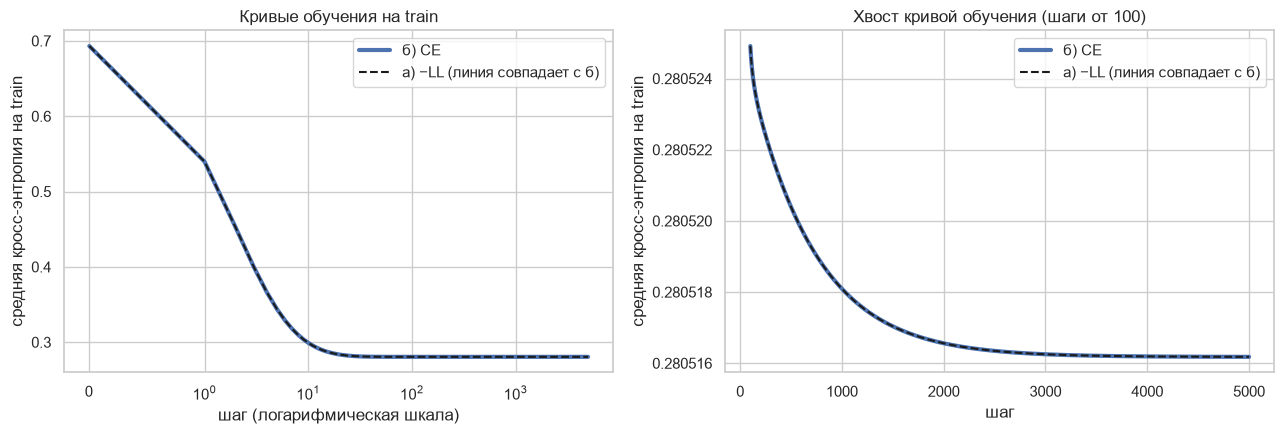

CE на шаге 0: 0.693147 (= ln 2 = 0.693147); на шаге 10: 0.299180; на шаге 100: 0.280525; на шаге 5000: 0.280516
Функция монотонно убывает (CE) / возрастает (LL): True True


In [13]:
h_LL, h_CE = models['LL'].history, models['CE'].history
steps = np.arange(MAX_STEPS + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(steps, h_CE, color='C0', lw=3, label='б) CE')
ax.plot(steps, -h_LL, color='k', ls='--', label='а) −LL (линия совпадает с б)')
ax.set_xscale('symlog', linthresh=1)
ax.set_xlabel('шаг (логарифмическая шкала)')
ax.set_ylabel('средняя кросс-энтропия на train')
ax.set_title('Кривые обучения на train')
ax.legend()

ax = axes[1]
tail = slice(100, None)
ax.plot(steps[tail], h_CE[tail], color='C0', lw=3, label='б) CE')
ax.plot(steps[tail], -h_LL[tail], color='k', ls='--', label='а) −LL (линия совпадает с б)')
ax.ticklabel_format(useOffset=False, style='plain', axis='y')
ax.set_xlabel('шаг')
ax.set_ylabel('средняя кросс-энтропия на train')
ax.set_title('Хвост кривой обучения (шаги от 100)')
ax.legend()
plt.tight_layout()
plt.show()

print(f'CE на шаге 0: {h_CE[0]:.6f} (= ln 2 = {np.log(2):.6f}); на шаге 10: {h_CE[10]:.6f}; '
      f'на шаге 100: {h_CE[100]:.6f}; на шаге {MAX_STEPS}: {h_CE[-1]:.6f}')
print('Функция монотонно убывает (CE) / возрастает (LL):',
      bool(np.all(np.diff(h_CE) <= 0)), bool(np.all(np.diff(h_LL) >= 0)))

Кривые способов а и б неразличимы: штриховая линия точно ложится на сплошную. $CE$ на train стартует с $\ln 2 = 0.693147$ (при $\theta = 0$ модель всем объектам даёт вероятность 0.5), к шагу 10 снижается до 0.299180, к шагу 100 — до 0.280525, а на шаге 5000 равна 0.280516. После сотого шага остаётся лишь медленное «дожимание» на 0.000009. Монотонность при $\alpha = 1$ подтверждает, что шаг выбран не слишком большим.

### 4.6. Базовые ориентиры и сводная таблица

Сравниваем с тремя ориентирами:

* **константа «всегда 0»** — не находит ни одного рискованного договора (F1 = 0);
* **константа «всегда 1»** — находит все рискованные договоры, но ценой огромного числа ложных тревог;
* **`sklearn.linear_model.LogisticRegression`** (`C = 1e6`, то есть почти без регуляризации, жёсткая точность решателя) на тех же стандартизованных признаках.

Для константной модели кросс-энтропия посчитана при $p = $ доле единиц в train (вероятностная константа без признаков); при $p = 0$ или $p = 1$ она была бы бесконечной.

In [14]:
sk_model = LogisticRegression(C=1e6, fit_intercept=False, tol=1e-12, max_iter=20000).fit(X_train, y_train)
theta_sk = sk_model.coef_[0]
p_const = y_train.mean()


def ce(p, y):
    return log_loss(y, p, labels=[0, 1])


summary = []
for name, pred_fn, ce_fn in [
    ('а) подъём по LL (своя реализация)', lambda X: models['LL'].predict(X), lambda X, y: models['LL'].CrossEntropy(X, y)),
    ('б) спуск по CE (своя реализация)', lambda X: models['CE'].predict(X), lambda X, y: models['CE'].CrossEntropy(X, y)),
    ('sklearn LogisticRegression', lambda X: sk_model.predict(X), lambda X, y: ce(sk_model.predict_proba(X)[:, 1], y)),
    ('константа «всегда 0»', lambda X: np.zeros(len(X), dtype=int), lambda X, y: ce(np.full(len(y), p_const), y)),
    ('константа «всегда 1»', lambda X: np.ones(len(X), dtype=int), lambda X, y: np.nan),
]:
    row = {'модель': name}
    for split, X_s, y_s in [('val', X_val, y_val), ('test', X_test, y_test)]:
        pred = pred_fn(X_s)
        row[f'accuracy {split}'] = accuracy(y_s, pred)
        row[f'F1 {split}'] = f1(y_s, pred)
    row['CE val'] = ce_fn(X_val, y_val)
    summary.append(row)
summary = pd.DataFrame(summary).set_index('модель')
display(summary.round(4))

print('Строка «константа „всегда 0“»: колонка CE посчитана при p = доле единиц в train.')
print(f'CE на train: способ б = {models["CE"].CrossEntropy(X_train, y_train):.8f}, sklearn = '
      f'{ce(sk_model.predict_proba(X_train)[:, 1], y_train):.8f}')
print('max |θ_б − θ_sklearn| =', np.max(np.abs(models['CE'].theta - theta_sk)))

,accuracy val,F1 val,accuracy test,F1 test,CE val
модель,,,,,
а) подъём по LL (своя реализация),0.9158,0.0000,0.9198,0.0000,0.2841
б) спуск по CE (своя реализация),0.9158,0.0000,0.9198,0.0000,0.2841
sklearn LogisticRegression,0.9158,0.0000,0.9198,0.0000,0.2841
константа «всегда 0»,0.9158,0.0000,0.9198,0.0000,0.2890
константа «всегда 1»,0.0842,0.1554,0.0802,0.1484,NaN


Строка «константа „всегда 0“»: колонка CE посчитана при p = доле единиц в train.
CE на train: способ б = 0.28051618, sklearn = 0.28051618
max |θ_б − θ_sklearn| = 0.0018616003628636468


Что видно:

* **Свои реализации и sklearn неотличимы по качеству.** Accuracy на validation и test — 0.9158 и 0.9198, F1 = 0, кросс-энтропия на validation 0.2841 у всех трёх. На train $CE$ у способа б и у sklearn совпадает до восьми знаков (0.28051618): градиентный метод дошёл до того же минимума.
* **Параметры отличаются слабо:** $\max|\theta_{\text{б}} - \theta_{\text{sklearn}}| = 0.0019$. Сильнее всего расходятся коэффициенты при `variable_4` и `variable_12` (0.08613 и −0.12483 у наших способов против 0.08800 и −0.12668 у sklearn, таблица в 4.7), остальные совпадают примерно до $10^{-5}$. Эти два признака сильно коррелированы (r = 0.990); вероятно, вдоль такого направления $CE$ почти плоская и градиентный метод сходится медленно, при этом на значение $CE$ разница в коэффициентах не влияет.
* **Константа «всегда 0»** даёт те же accuracy 0.9158 и 0.9198 и F1 = 0, то есть при пороге 0.5 наши модели от неё не отличаются. Константа «всегда 1» даёт F1 0.1554 (validation) и 0.1484 (test) при accuracy 0.0842 и 0.0802.
* **По кросс-энтропии модель всё же лучше константы:** 0.2841 на validation против 0.2890 у константной вероятности (доля единиц в train). Выигрыш небольшой: признаки несут мало информации о риске.

### 4.7. Совпадают ли траектории способов а и б

Если $LL(\theta) = -CE(\theta)$ для любого $\theta$, то и градиенты отличаются знаком, а значит, шаги подъёма по $LL$ и спуска по $CE$ одинаковы. Проверим это численно: сравним итоговые параметры, значения функции на **всех** шагах и прогнозы.

In [15]:
th_LL, th_CE = models['LL'].theta, models['CE'].theta
print('max |θ_LL − θ_CE|                 =', np.max(np.abs(th_LL - th_CE)))
print('max по шагам |LL(θₖ) + CE(θₖ)|    =', np.max(np.abs(models['LL'].history + models['CE'].history)))
print('прогнозы а и б различаются на val / test в',
      int(np.sum(models['LL'].predict(X_val) != models['CE'].predict(X_val))), '/',
      int(np.sum(models['LL'].predict(X_test) != models['CE'].predict(X_test))), 'объектах')
print('θ_LL совпадает с θ_CE побитово:', bool(np.array_equal(th_LL, th_CE)))

display(pd.DataFrame({'а) подъём LL': th_LL, 'б) спуск CE': th_CE, 'sklearn': theta_sk},
                     index=['свободный член'] + FEATURES).round(5))

max |θ_LL − θ_CE|                 = 0.0
max по шагам |LL(θₖ) + CE(θₖ)|    = 0.0
прогнозы а и б различаются на val / test в 0 / 0 объектах
θ_LL совпадает с θ_CE побитово: True


,а) подъём LL,б) спуск CE,sklearn
свободный член,-2.46229,-2.46229,-2.46230
variable_4,0.08613,0.08613,0.08800
variable_6,0.02961,0.02961,0.02961
variable_12,-0.12483,-0.12483,-0.12668
variable_13,-0.21618,-0.21618,-0.21619
variable_14,0.04848,0.04848,0.04848
variable_16,-0.01883,-0.01883,-0.01884
variable_17,0.03105,0.03105,0.03105
variable_18,-0.00416,-0.00416,-0.00417
variable_19,-0.12818,-0.12818,-0.12817


Численная проверка подтверждает теорию:

* $\max|\theta_{LL} - \theta_{CE}| = 0.0$: итоговые параметры совпадают до последнего бита (`np.array_equal` вернул `True`);
* $\max_k |LL(\theta_k) + CE(\theta_k)| = 0.0$: значения функции совпадают на каждом из 5001 значений истории, то есть траектории не расходились ни на одном шаге;
* прогнозы а и б не отличаются ни на одном объекте validation и test.

Точный ноль, а не $\sim 10^{-16}$, получился потому, что в нашей реализации градиент для б считается как $X^\top (h - y)/n$ и отличается от градиента для а только знаком, а смена знака в арифметике с плавающей точкой не вносит ошибки. При другом порядке вычислений расхождение определялось бы только ошибками округления порядка $10^{-16}$ на шаг.

## 5. Порог классификации

При дисбалансе классов порог $0.5$ почти бесполезен: модель редко бывает достаточно уверена в единице. Порог — это не параметр обучения, а параметр решающего правила, поэтому его можно подбирать отдельно. Делаем так:

1. перебираем пороги от 0.01 до 0.99 с шагом 0.005 и для каждого считаем F1 на **validation**;
2. берём порог $\tau^*$ с максимальной validation-F1;
3. один раз оцениваем модель на **test** с порогом $\tau^*$ (на test порог не подбираем).

In [16]:
thresholds = np.linspace(0.01, 0.99, 197)


def sweep(model, X, y):
    p = model.predict_proba(X)
    pred = [p >= t for t in thresholds]
    return (np.array([precision(y, q) for q in pred]),
            np.array([recall(y, q) for q in pred]),
            np.array([f1(y, q) for q in pred]))


tuned = {}
for mode in ('LL', 'CE'):
    P, R, F = sweep(models[mode], X_val, y_val)
    best = int(np.argmax(F))
    tuned[mode] = {'tau': thresholds[best], 'P': P, 'R': R, 'F': F}

rows = []
for mode in ('LL', 'CE'):
    tau = tuned[mode]['tau']
    for label, t in [('0.5', 0.5), (f'τ* = {tau:.3f}', tau)]:
        row = {'способ': names[mode], 'порог': label}
        for split, (X_s, y_s) in [('val', (X_val, y_val)), ('test', (X_test, y_test))]:
            pred = models[mode].predict(X_s, threshold=t)
            row[f'accuracy {split}'] = accuracy(y_s, pred)
            row[f'precision {split}'] = precision(y_s, pred)
            row[f'recall {split}'] = recall(y_s, pred)
            row[f'F1 {split}'] = f1(y_s, pred)
        row['доля прогнозов «1» на test'] = float(np.mean(models[mode].predict(X_test, threshold=t)))
        rows.append(row)
threshold_table = pd.DataFrame(rows).set_index(['способ', 'порог'])
display(threshold_table.round(4))

tau_star = tuned['CE']['tau']
print(f'Порог τ*: способ а = {tuned["LL"]["tau"]:.3f}, способ б = {tuned["CE"]["tau"]:.3f}')
print(f'F1 на validation: при τ = {thresholds[0]:.2f} — {tuned["CE"]["F"][0]:.4f}, максимум (при τ*) — {tuned["CE"]["F"].max():.4f}')
print(f'Доля единиц: validation {y_val.mean():.4f}, test {y_test.mean():.4f}')
f1_all_ones_test = f1(y_test, np.ones(len(y_test), dtype=int))
print(f'F1 константы «всегда 1»: validation {f1(y_val, np.ones(len(y_val), dtype=int)):.4f}, test {f1_all_ones_test:.4f}')
print(f'ROC-AUC модели (диагностика, не метрика задания): validation '
      f'{roc_auc_score(y_val, models["CE"].predict_proba(X_val)):.4f}, test '
      f'{roc_auc_score(y_test, models["CE"].predict_proba(X_test)):.4f}')

accuracy val  precision val  recall val  F1 val  \
способ          порог                                                         
а) подъём по LL 0.5               0.9158         0.0000      0.0000  0.0000   
                τ* = 0.100        0.7261         0.1264      0.3809  0.1898   
б) спуск по CE  0.5               0.9158         0.0000      0.0000  0.0000   
                τ* = 0.100        0.7261         0.1264      0.3809  0.1898   

                            accuracy test  precision test  recall test  \
способ          порог                                                    
а) подъём по LL 0.5                0.9198          0.0000       0.0000   
                τ* = 0.100         0.7308          0.1227       0.3837   
б) спуск по CE  0.5                0.9198          0.0000       0.0000   
                τ* = 0.100         0.7308          0.1227       0.3837   

                            F1 test  доля прогнозов «1» на test  
способ          порог                                            
а) подъём по LL 0.5           0.000                      0.0000  
                τ* = 0.100    0.186                      0.2506  
б) спуск по CE  0.5           0.000                      0.0000  
                τ* = 0.100    0.186                      0.2506

Порог τ*: способ а = 0.100, способ б = 0.100
F1 на validation: при τ = 0.01 — 0.1554, максимум (при τ*) — 0.1898
Доля единиц: validation 0.0842, test 0.0802
F1 константы «всегда 1»: validation 0.1554, test 0.1484
ROC-AUC модели (диагностика, не метрика задания): validation 0.6019, test 0.6016


Матрица ошибок на test, порог 0.500: [[TN, FP], [FN, TP]] = [[20218, 0], [1762, 0]]
Матрица ошибок на test, порог 0.100: [[TN, FP], [FN, TP]] = [[15386, 4832], [1086, 676]]; ложных тревог на одну верно найденную единицу: 7.1


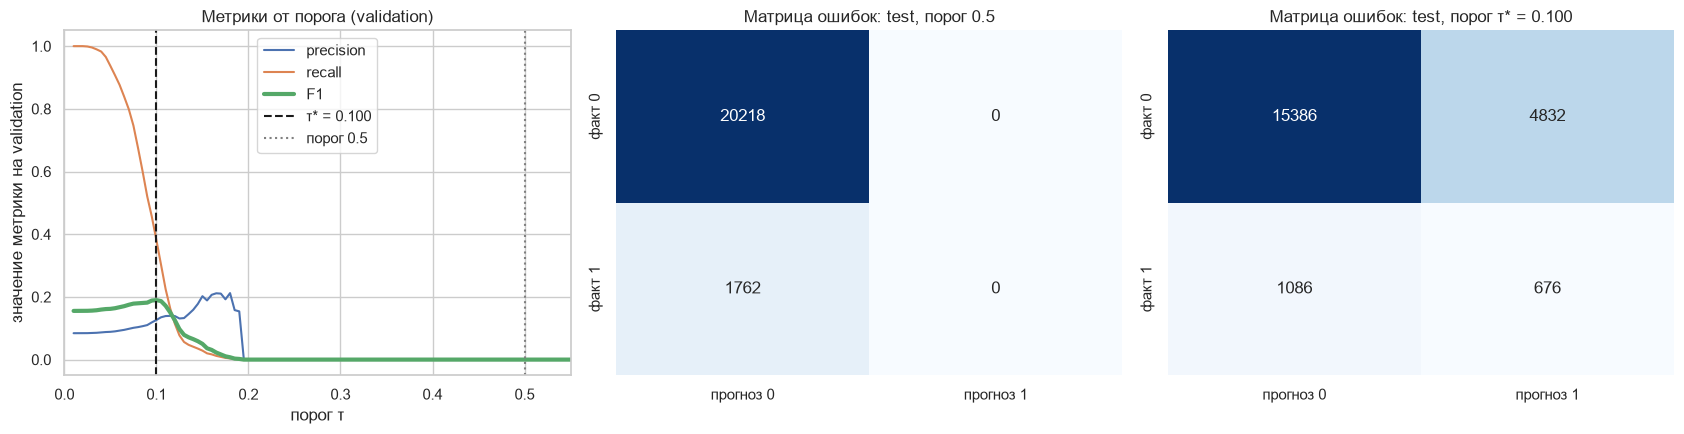

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ax = axes[0]
t_ = tuned['CE']
ax.plot(thresholds, t_['P'], label='precision')
ax.plot(thresholds, t_['R'], label='recall')
ax.plot(thresholds, t_['F'], lw=3, label='F1')
ax.axvline(t_['tau'], color='k', ls='--', label=f'τ* = {t_["tau"]:.3f}')
ax.axvline(0.5, color='gray', ls=':', label='порог 0.5')
ax.set_xlim(0, 0.55)
ax.set_xlabel('порог τ')
ax.set_ylabel('значение метрики на validation')
ax.set_title('Метрики от порога (validation)')
ax.legend()

for ax, t, title in [(axes[1], 0.5, 'test, порог 0.5'), (axes[2], tau_star, f'test, порог τ* = {tau_star:.3f}')]:
    cm = confusion_matrix_np(y_test, models['CE'].predict(X_test, threshold=t))
    print(f'Матрица ошибок на test, порог {t:.3f}: [[TN, FP], [FN, TP]] = {cm.tolist()}'
          + (f'; ложных тревог на одну верно найденную единицу: {cm[0, 1] / cm[1, 1]:.1f}' if cm[1, 1] > 0 else ''))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['прогноз 0', 'прогноз 1'], yticklabels=['факт 0', 'факт 1'])
    ax.set_title('Матрица ошибок: ' + title)
plt.tight_layout()
plt.show()

Что получилось (по таблице, графикам и выводу выше):

* **Порог 0.5 бесполезен:** F1 = 0, модель не нашла ни одного из 1762 рискованных договоров test.
* **Порог, подобранный по validation,** $\tau^* = 0.100$ (одинаковый для способов а и б). На validation F1 = 0.1898 при precision 0.1264 и recall 0.3809. Диапазон невелик: при $\tau = 0.01$, когда почти всем договорам ставится «1», F1 равна 0.1554, в максимуме 0.1898. Правее $\tau \approx 0.2$ метрики равны нулю, так как вероятностей выше этого уровня модель почти не выдаёт.
* **Оценка на test при том же $\tau^*$** (на test порог не подбирался): F1 = 0.186, precision 0.1227, recall 0.3837, accuracy 0.7308. Матрица ошибок: TP = 676, FP = 4832, FN = 1086, TN = 15386. F1 на test и на validation близки (0.186 и 0.1898), то есть порог не «подогнан» под validation (это одно разбиение, и кривая F1 по порогу справа от $\tau^*$ довольно крутая, так что вывод осторожный).
* **F1 остаётся низким, и это честный результат, а не ошибка кода.** Константа «всегда 1» даёт на test F1 0.1484, модель с подобранным порогом — 0.186, то есть выигрыш около 0.04. ROC-AUC равна 0.6019 на validation и 0.6016 на test: десять выбранных признаков при линейной модели разделяют классы слабо. sklearn достигает того же минимума кросс-энтропии (раздел 4.6), так что дело не в недообучении. Показатели не подгонялись.
* **Цена порога:** accuracy падает с 0.9198 до 0.7308, доля прогнозов «1» на test 0.2506 при реальной доле 0.0802, на одну верно найденную единицу приходится около 7.1 ложных тревог. Нужен ли такой порог, зависит от цены ошибок: если пропуск рискованного договора обходится заметно дороже ложной тревоги, порог ниже 0.5 оправдан.

## 6. Выводы

**1. Что сделано.** Реализован класс `LogisticRegressionGD` (numpy, без циклов по объектам, с устойчивыми сигмоидой и логарифмом) с двумя режимами обучения: градиентный подъём по логарифмическому правдоподобию (а) и градиентный спуск по кросс-энтропии (б). Свои accuracy, precision, recall, F1 и матрица ошибок совпали с `sklearn.metrics` на пяти случайных наборах (включая случай без единиц в прогнозе) и, для accuracy и F1, на реальных прогнозах модели при пороге 0.5 (там все прогнозы нулевые).

**2. Способы а и б математически эквивалентны.** Для любого $\theta$ верно $LL(\theta) = -CE(\theta)$, поэтому $\nabla CE(\theta) = -\nabla LL(\theta)$. Тогда шаг спуска по $CE$ равен

$$\theta - \alpha \nabla CE(\theta) = \theta - \alpha\bigl(-\nabla LL(\theta)\bigr) = \theta + \alpha \nabla LL(\theta),$$

то есть совпадает с шагом подъёма по $LL$. Условия эквивалентности: оба критерия берутся как среднее по выборке (если LL взять суммой, а CE средним, шаги различались бы множителем $n$), старт $\theta^{(0)} = 0$, скорость $\alpha$ и число шагов $K$ одинаковые, критерий останова не используется (при остановке по порогу ошибки отрицательное LL и положительное CE вели бы себя по-разному). Поэтому по индукции $\theta^{(k)}_{LL} = \theta^{(k)}_{CE}$ для всех $k$. Отсюда одинаковы вероятности, прогнозы, accuracy и F1, а значения функций на каждом шаге отличаются только знаком. Подъём по $LL$ и спуск по $CE$ — один и тот же алгоритм, записанный с разными знаками.

Численная проверка (раздел 4.7): $\max|\theta_{LL} - \theta_{CE}| = 0.0$, $\max_k|LL(\theta_k) + CE(\theta_k)| = 0.0$, прогнозы совпали на всех объектах validation и test. Результаты при $\alpha = 1$, $K = 5000$ и пороге 0.5:

| способ | accuracy val | F1 val | accuracy test | F1 test |
|---|---|---|---|---|
| а) подъём по LL | 0.9158 | 0.0000 | 0.9198 | 0.0000 |
| б) спуск по CE | 0.9158 | 0.0000 | 0.9198 | 0.0000 |

**3. Время.** При одинаковых $\alpha$ и $K$ медиана времени обучения: а — 15.340 с, б — 15.343 с, относительная разница — менее 0.1 %. Это меньше разброса повторов (0.01 и 0.01 с), то есть различие не значимо: в другом запуске быстрее может оказаться любой из способов. Иначе и быть не должно, потому что оба способа выполняют одни и те же вычисления и отличаются лишь знаком. Считать результат закономерностью «один способ быстрее» нельзя.

**4. Качество на `insclass_train.csv`.**

* При пороге 0.5 модель не предсказывает ни одного рискованного договора: F1 = 0, accuracy равна доле нулей (0.9158 на validation, 0.9198 на test), как у константы «всегда 0». Максимальная предсказанная вероятность около 0.26.
* Порог $\tau^* = 0.100$, подобранный по validation, даёт на test F1 = 0.186 (precision 0.1227, recall 0.3837), при этом accuracy падает до 0.7308. Это лишь немного лучше константы «всегда 1» (F1 0.1484). ROC-AUC около 0.60.
* Кросс-энтропия на validation 0.2841 против 0.2890 у константной вероятности: признаки несут мало информации. Низкий F1 — свойство данных и линейной модели на этих признаках, а не дефект реализации: sklearn приходит к тому же значению кросс-энтропии на train (0.28051618).

**5. Оговорки.**

* Удаление строк с пропусками убрало 4877 строк (3.22 %), и среди них доля рискованных 48.64 % против 8.25 % в оставшихся. Сам факт пропуска сильно связан с риском, а модель его не использует; на новых данных с пропусками качество будет другим.
* Использовано одно случайное разбиение (seed 42): оценки на test имеют случайную ошибку, доверительные интервалы не строились.
* Разница между $\alpha = 0.5$ и $\alpha = 1$ по validation $CE$ лежит в шестом знаке, эти значения практически равноценны.
* В игрушечном примере на «сырых» $x$ за 10000 шагов метод не дошёл до оптимума ($CE$ 0.36681 против 0.36500), что и объясняет стандартизацию признаков в основном эксперименте.